# Task 5: Limited hyperparameter optimisation (Siamese network)

## What is tuned and why

| Hyperparameter | Values | What it controls |
|---|---|---|
| Triplet **margin** | 0.2, 0.5, 1.0 | How much further a different writer must be than the same writer. Embeddings lie on the unit sphere, so squared distances range from 0 to 4. |
| **Embedding size** | 16, 64 | How many numbers describe a writer's style (capacity). |

Fixed: architecture, augmentation, Adam (learning rate 0.001), batch size 128, 15,000 fresh triplets
per epoch, early stopping (patience 3, at most 15 epochs).

## Protocol

- Same split as the CNN: train on **sessions 1–3** of all 20 writers, validate on **session 4**.
  **Session 5 is not used here**; it is the test set for the comparison in Task 6.
- **Validation score:** AUC for same-writer vs different-writer pairs, where a session-4 image is
  compared with a session 1–3 image of the same digit. Also reported: writer identification
  accuracy on session 4 by nearest prototype (mean embedding of each writer × digit from sessions 1–3).
- Each grid point is trained once (seed 0). The default setting (margin 0.5, size 64) is repeated
  with two more seeds, to measure how much results move by chance alone. A difference between
  settings smaller than that spread should not be read as a real effect.

In [1]:
import sys
sys.path.append("../src")
import os, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_utils import load_handwriting
from siamese import (make_index_table, make_pairs, train_siamese, embed, pair_distance,
                     verification_metrics, prototypes, identify)

images, meta = load_handwriting()
x = images[..., None]
y = meta.person_id.to_numpy()
table = make_index_table(meta)
session = meta.session.to_numpy()
all_writers = np.arange(1, 21)
train_rows = np.where(session <= 3)[0]
val_rows = np.where(session == 4)[0]
Path("../results").mkdir(exist_ok=True)

# Validation pairs: session-4 image vs session 1-3 image, same digit, all writers
v1, v2, v_label, _ = make_pairs(table, all_writers, 6000, np.random.default_rng(42),
                                sessions=[4], ref_sessions=[1, 2, 3])

def val_auc(embedding):
    e = embed(embedding, x[np.r_[v1, v2]])
    return verification_metrics(((e[:len(v1)] - e[len(v1):]) ** 2).sum(1), v_label)["AUC"]

I0000 00:00:1792107314.682875    2054 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792107315.770727    2054 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
grid = [(margin, dim, 0) for margin in [0.2, 0.5, 1.0] for dim in [16, 64]]
grid += [(0.5, 64, 1), (0.5, 64, 2)]          # seed repeats of the default

rows, best_auc = [], -1
for margin, dim, seed in grid:
    start = time.time()
    embedding, hist = train_siamese(x, table, all_writers, [1, 2, 3], val_auc,
                                    dim=dim, margin=margin, n_triplets=15000,
                                    max_epochs=15, patience=3, seed=seed, verbose=False)
    emb = embed(embedding, x)
    ver = verification_metrics(pair_distance(emb, v1, v2), v_label)
    proto, proto_writer = prototypes(emb, meta, train_rows)
    top1, top3 = identify(emb[val_rows], proto, proto_writer)
    rows.append({"margin": margin, "embedding size": dim, "seed": seed,
                 "epochs": len(hist), "val AUC": ver["AUC"], "val EER": ver["EER"],
                 "val identification": (top1 == y[val_rows]).mean(),
                 "val top-3": (top3 == y[val_rows][:, None]).any(axis=1).mean(),
                 "minutes": (time.time() - start) / 60})
    print(rows[-1])
    if ver["AUC"] > best_auc:
        best_auc = ver["AUC"]
        embedding.save_weights("../results/siamese_best.weights.h5")

hpo = pd.DataFrame(rows)
hpo.to_csv("../results/siamese_hpo.csv", index=False)
hpo.round(3)

{'margin': 0.2, 'embedding size': 16, 'seed': 0, 'epochs': 6, 'val AUC': 0.9390827777777777, 'val EER': np.float64(0.135), 'val identification': np.float64(0.5836), 'val top-3': np.float64(0.7982), 'minutes': 1.927460777759552}


{'margin': 0.2, 'embedding size': 64, 'seed': 0, 'epochs': 6, 'val AUC': 0.9355112222222222, 'val EER': np.float64(0.14283333333333337), 'val identification': np.float64(0.6006), 'val top-3': np.float64(0.8012), 'minutes': 2.0224168062210084}


{'margin': 0.5, 'embedding size': 16, 'seed': 0, 'epochs': 12, 'val AUC': 0.9425386666666666, 'val EER': np.float64(0.1355), 'val identification': np.float64(0.5788), 'val top-3': np.float64(0.8222), 'minutes': 4.051874919732412}


{'margin': 0.5, 'embedding size': 64, 'seed': 0, 'epochs': 15, 'val AUC': 0.9479492222222222, 'val EER': np.float64(0.12966666666666665), 'val identification': np.float64(0.608), 'val top-3': np.float64(0.8474), 'minutes': 5.0720664978027346}


{'margin': 1.0, 'embedding size': 16, 'seed': 0, 'epochs': 11, 'val AUC': 0.9336828888888888, 'val EER': np.float64(0.1436666666666666), 'val identification': np.float64(0.556), 'val top-3': np.float64(0.8172), 'minutes': 3.521166928609212}


{'margin': 1.0, 'embedding size': 64, 'seed': 0, 'epochs': 12, 'val AUC': 0.9389217777777777, 'val EER': np.float64(0.13816666666666672), 'val identification': np.float64(0.5522), 'val top-3': np.float64(0.8014), 'minutes': 4.495649230480194}


{'margin': 0.5, 'embedding size': 64, 'seed': 1, 'epochs': 15, 'val AUC': 0.949296888888889, 'val EER': np.float64(0.12683333333333335), 'val identification': np.float64(0.6268), 'val top-3': np.float64(0.805), 'minutes': 5.132800706227621}


{'margin': 0.5, 'embedding size': 64, 'seed': 2, 'epochs': 7, 'val AUC': 0.9429826666666666, 'val EER': np.float64(0.13583333333333342), 'val identification': np.float64(0.5872), 'val top-3': np.float64(0.85), 'minutes': 2.406338651974996}


,margin,embedding size,seed,epochs,val AUC,val EER,val identification,val top-3,minutes
0,0.2,16,0,6,0.939,0.135,0.584,0.798,1.927
1,0.2,64,0,6,0.936,0.143,0.601,0.801,2.022
2,0.5,16,0,12,0.943,0.136,0.579,0.822,4.052
3,0.5,64,0,15,0.948,0.130,0.608,0.847,5.072
4,1.0,16,0,11,0.934,0.144,0.556,0.817,3.521
5,1.0,64,0,12,0.939,0.138,0.552,0.801,4.496
6,0.5,64,1,15,0.949,0.127,0.627,0.805,5.133
7,0.5,64,2,7,0.943,0.136,0.587,0.850,2.406


## Sensitivity

Default setting (margin 0.5, size 64) over 3 seeds:
      val AUC  val identification
mean    0.947               0.607
min     0.943               0.587
max     0.949               0.627
std     0.003               0.020


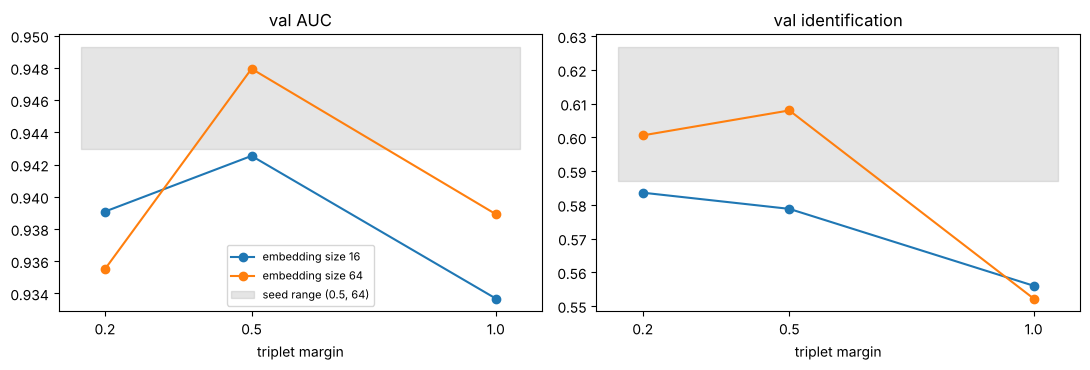

In [3]:
seed_runs = hpo[(hpo.margin == 0.5) & (hpo["embedding size"] == 64)]
spread = seed_runs[["val AUC", "val identification"]].agg(["mean", "min", "max", "std"])
print("Default setting (margin 0.5, size 64) over 3 seeds:")
print(spread.round(3))

grid_runs = hpo[hpo.seed == 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric in zip(axes, ["val AUC", "val identification"]):
    for dim, g in grid_runs.groupby("embedding size"):
        ax.plot(g.margin, g[metric], marker="o", label=f"embedding size {dim}")
    ax.fill_between([0.15, 1.05], seed_runs[metric].min(), seed_runs[metric].max(),
                    color="grey", alpha=0.2, label="seed range (0.5, 64)")
    ax.set_xlabel("triplet margin")
    ax.set_title(metric)
    ax.set_xticks([0.2, 0.5, 1.0])
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [4]:
best = hpo.sort_values("val AUC", ascending=False).iloc[0]
print("Chosen by validation AUC:", dict(best[["margin", "embedding size", "seed"]]))
print("Range of validation AUC across the grid:",
      round(grid_runs["val AUC"].min(), 3), "to", round(grid_runs["val AUC"].max(), 3))
print("Range of validation identification:",
      round(grid_runs["val identification"].min(), 3), "to",
      round(grid_runs["val identification"].max(), 3))

Chosen by validation AUC: {'margin': np.float64(0.5), 'embedding size': np.float64(64.0), 'seed': np.float64(1.0)}
Range of validation AUC across the grid: 0.934 to 0.948
Range of validation identification: 0.552 to 0.608


## Notes for the report (in your own words)

- Compare the range across the grid with the seed range of the default setting. If the grid
  range is not much wider, the model is **insensitive** to these hyperparameters within the
  ranges tried, and the "best" setting partly reflects chance.
- Say which measure moves more (AUC or identification accuracy) and why: identification depends
  on the ranking of 20 writers, so small changes in the embedding can flip the top choice.
- The chosen setting is picked on session 4 only. Its session-5 performance is reported in Task 6.
- Limits: one seed per grid point, two hyperparameters, a small grid. A wider search (learning
  rate, number of triplets, harder negatives) was not done for time reasons.